# Fashion MNIST Classification Project

**Goal:** Train a convolutional neural network (CNN) in PyTorch to classify grayscale clothing images from Fashion-MNIST.

This notebook:
1. Loads and explores the dataset.
2. Preprocesses images.
3. Defines and trains a CNN.
4. Evaluates test accuracy and loss.
5. Visualizes predictions.

**Note:** The first run may need internet access to download Fashion-MNIST. If the course provides a starter notebook, compare this notebook with its required cells and rubric before submitting.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 1. Load and preprocess Fashion-MNIST

In [2]:
# Convert images to tensors and normalize grayscale values.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Training images: {len(train_dataset)}")
print(f"Test images: {len(test_dataset)}")

100%|██████████| 26.4M/26.4M [00:01<00:00, 17.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 305kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.62MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 5.49MB/s]

Training images: 60000
Test images: 10000


## 2. Inspect sample images

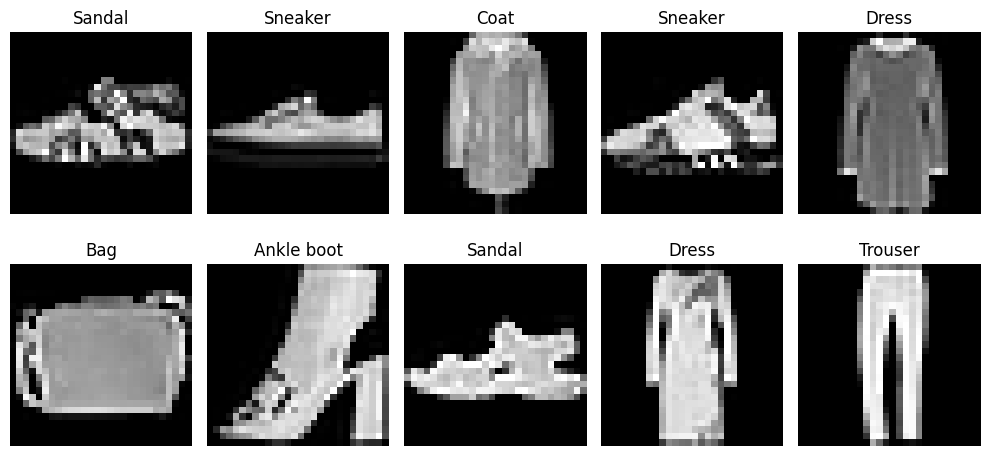

In [3]:
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    # Undo normalization for display
    image = images[i].squeeze().numpy() * 0.5 + 0.5
    ax.imshow(image, cmap="gray")
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Define the CNN

In [4]:
class FashionCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # 28x28 -> 14x14
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)   # 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = FashionCNN().to(device)
print(model)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 4. Set the loss function and optimizer

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# CrossEntropyLoss expects raw class scores (logits), so do not apply Softmax
# inside the model during training.

## 5. Train the model

In [6]:
num_epochs = 5
train_losses = []
train_accuracies = []

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()
        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_images.size(0)
        predictions = outputs.argmax(dim=1)
        total += batch_labels.size(0)
        correct += (predictions == batch_labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} | Accuracy: {epoch_accuracy:.2%}"
    )

Epoch [1/5] Loss: 0.5126 | Accuracy: 81.67%
Epoch [2/5] Loss: 0.3311 | Accuracy: 88.27%
Epoch [3/5] Loss: 0.2794 | Accuracy: 89.82%
Epoch [4/5] Loss: 0.2482 | Accuracy: 90.99%
Epoch [5/5] Loss: 0.2256 | Accuracy: 91.78%


## 6. Evaluate on the test set

In [7]:
model.eval()
test_loss_sum = 0.0
correct = 0
total = 0

with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)

        test_loss_sum += loss.item() * batch_images.size(0)
        predictions = outputs.argmax(dim=1)
        total += batch_labels.size(0)
        correct += (predictions == batch_labels).sum().item()

test_loss = test_loss_sum / total
test_accuracy = correct / total

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test loss: 0.2546
Test accuracy: 90.97%


## 7. Plot training metrics

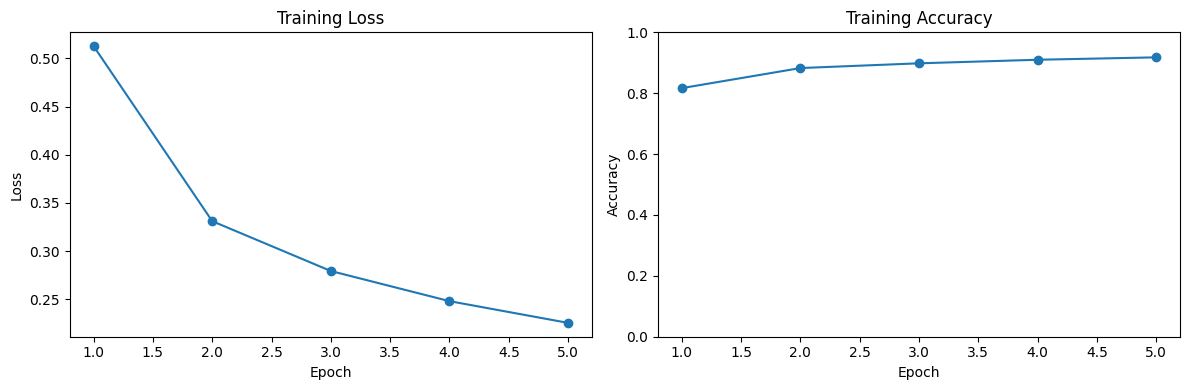

In [8]:
epochs = range(1, num_epochs + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, train_losses, marker="o")
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[1].plot(epochs, train_accuracies, marker="o")
axes[1].set_title("Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 8. Visualize model predictions

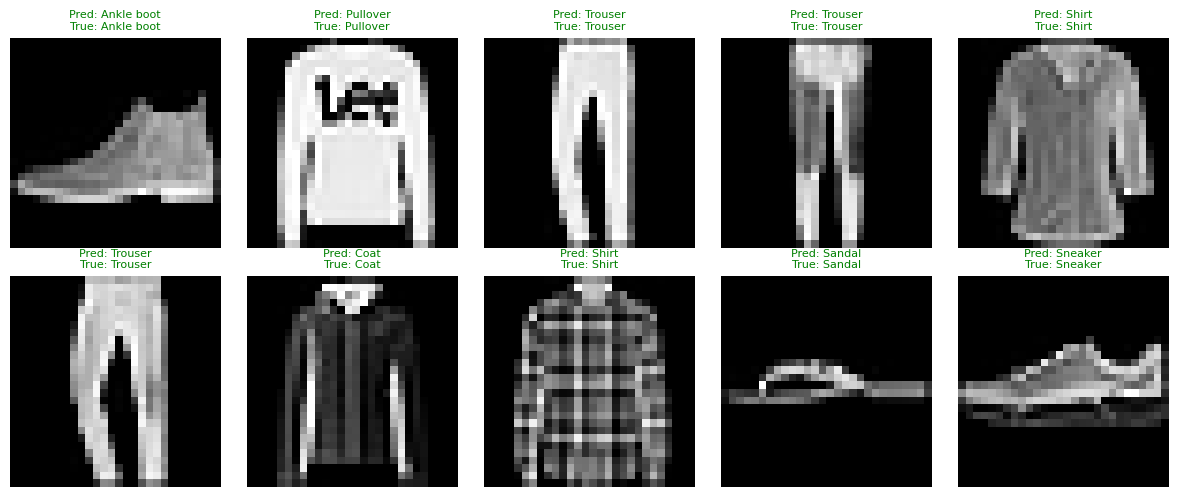

In [9]:
images, labels = next(iter(test_loader))
images_device = images.to(device)

model.eval()
with torch.no_grad():
    outputs = model(images_device)
    predictions = outputs.argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    image = images[i].squeeze().numpy() * 0.5 + 0.5
    true_label = class_names[labels[i].item()]
    predicted_label = class_names[predictions[i].item()]
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Pred: {predicted_label}\nTrue: {true_label}",
                 color=("green" if predictions[i] == labels[i] else "red"),
                 fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Conclusion

A convolutional neural network was built and trained to classify the 10 Fashion-MNIST clothing categories. The convolution and pooling layers learn visual features, while the fully connected layers use those features to predict the class.

The test accuracy printed above is the final evaluation result for this run. Results can vary slightly by hardware and training environment. Possible improvements include training for more epochs, tuning the learning rate, and adding data augmentation.